In [1]:
import numpy as np 
import pandas as pd
import scanpy as sc
import anndata as ad 
import os

## 读取处理好的单细胞rna数据

In [2]:
scdata = sc.read_h5ad('/home/rsun@ZHANGroup.local/sly_data/sly_05_require/multi_modify.h5ad')
print(scdata.shape)

(21723, 9911)


/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:378: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


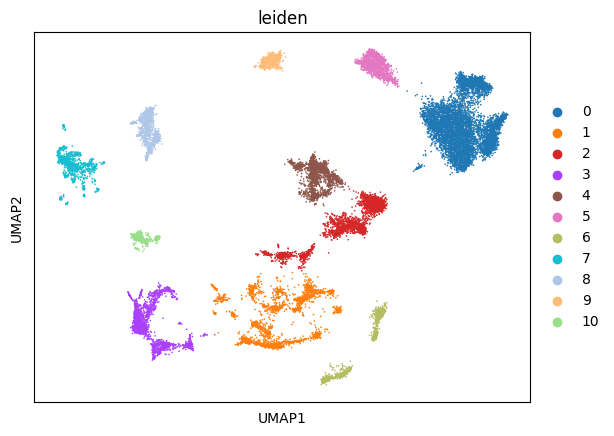

In [4]:
sc.pl.umap(scdata, color = 'leiden')

## 读取raw count 数据

In [46]:
cydata = sc.read_10x_h5('/home/rsun@ZHANGroup.local/sly_data/data/CY/CYHM/filtered_feature_bc_matrix.h5')
cydata.var_names_make_unique()
print(cydata.shape)

jtdata = sc.read_10x_h5('/home/rsun@ZHANGroup.local/sly_data/data/JT/JTHM/filtered_feature_bc_matrix.h5')
jtdata.var_names_make_unique()
print(jtdata.shape)

mdata = sc.read_10x_h5('/home/rsun@ZHANGroup.local/sly_data/data/M/MHM/filtered_feature_bc_matrix.h5')
mdata.var_names_make_unique()
print(mdata.shape)

qfdata = sc.read_10x_h5('/home/rsun@ZHANGroup.local/sly_data/data/QF/QFHM/outs/filtered_feature_bc_matrix.h5')
qfdata.var_names_make_unique()
print(qfdata.shape) 

tdata = sc.read_10x_h5('/home/rsun@ZHANGroup.local/sly_data/data/T/THM/filtered_feature_bc_matrix.h5')
tdata.var_names_make_unique()
print(tdata.shape)

(9251, 23533)
(9527, 21815)


/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/anndata/_core/anndata.py:1908: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


(8572, 32285)
(12068, 20319)


/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/anndata/_core/anndata.py:1908: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


(10413, 23848)


In [47]:
import json 

with open('/home/rsun@ZHANGroup.local/sly_data/genome/mfu_gene_map.json', 'r') as f:
    cymap = json.load(f) 

with open('/home/rsun@ZHANGroup.local/sly_data/genome/csp_gene_map.json', 'r') as f:
    qfmap = json.load(f) 

with open('/home/rsun@ZHANGroup.local/sly_data/genome/rsi_gene_map.json', 'r') as f:
    jtmap = json.load(f) 

with open('/home/rsun@ZHANGroup.local/sly_data/genome/tda_gene_map.json', 'r') as f:
    tmap = json.load(f)

def gene_map(adata, map):
    gene = adata.var.index.values
    for i,ele in enumerate(gene):
        if ele in map:
            gene[i] = map[ele].capitalize()
    adata.var.index = gene
    adata.var_names_make_unique()
    return adata, adata.var.index.values

cydata, cygene = gene_map(cydata, cymap)
qfdata, qfgene = gene_map(qfdata, qfmap)
jtdata, jtgene = gene_map(jtdata, jtmap)
tdata, tgene = gene_map(tdata, tmap)

mutual_gene = np.intersect1d(cygene, np.intersect1d(qfgene, np.intersect1d(jtgene, tgene)))
print(mutual_gene.shape)
mutual_gene = np.intersect1d(mutual_gene,mdata.var.index.values)
print(mutual_gene.shape)

(10166,)
(10149,)


In [48]:
cydata = cydata[:,mutual_gene]
jtdata = jtdata[:,mutual_gene]
qfdata = qfdata[:,mutual_gene]
mdata = mdata[:,mutual_gene]
tdata = tdata[:,mutual_gene]

### 修改obs index

In [51]:
cydata.obs.index = 'CYHM-' + cydata.obs.index.values
jtdata.obs.index = 'JTHM-' + jtdata.obs.index.values
qfdata.obs.index = 'QFHM-' + qfdata.obs.index.values
mdata.obs.index = 'MHM-' + mdata.obs.index.values
tdata.obs.index = 'THM-' + tdata.obs.index.values

adata = ad.concat([cydata, jtdata, qfdata, mdata, tdata])
adata

AnnData object with n_obs × n_vars = 49831 × 10149

In [52]:
adata.var = mdata.var
adata = adata[:,scdata.var.index]
adata

View of AnnData object with n_obs × n_vars = 49831 × 9911
    var: 'gene_ids', 'feature_types', 'genome'

### 保留共有 obs

In [53]:
mutual_idx = np.intersect1d(adata.obs.index, scdata.obs.index)
print(mutual_idx.shape)
adata = adata[mutual_idx,:]
scdata = scdata[mutual_idx,:]

(21723,)


In [58]:
adata.obsm['X_umap'] = scdata.obsm['X_umap'].copy()
adata.obsm['X_pca'] = scdata.obsm['X_pca'].copy()
adata.obsm['X_pca_harmony'] = scdata.obsm['X_pca_harmony'].copy()
adata.obs = scdata.obs.loc[:,['leiden', 'eco','species']]
adata

/tmp/ipykernel_1491204/3472642750.py:1: ImplicitModificationWarning: Setting element `.obsm['X_umap']` of view, initializing view as actual.
  adata.obsm['X_umap'] = scdata.obsm['X_umap'].copy()


AnnData object with n_obs × n_vars = 21723 × 9911
    obs: 'leiden', 'eco', 'species'
    var: 'gene_ids', 'feature_types', 'genome'
    obsm: 'X_umap', 'X_pca', 'X_pca_harmony'

In [62]:
adata.write('multi_rna_raw.h5ad')

## scenicplus 教程

In [63]:
adata.raw = adata 
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5)
adata = adata[:, adata.var.highly_variable]
sc.pp.scale(adata, max_value=10)
adata

/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/scanpy/preprocessing/_simple.py:843: UserWarning: Revieved a view of an AnnData. Making a copy.
  view_to_actual(adata)


AnnData object with n_obs × n_vars = 21723 × 1813
    obs: 'leiden', 'eco', 'species'
    var: 'gene_ids', 'feature_types', 'genome', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'log1p', 'hvg'
    obsm: 'X_umap', 'X_pca', 'X_pca_harmony'

In [64]:
adata.write('multi_rna_scenicplut.h5ad')